# Matrix Rank — From Information Bottlenecks to LoRA

> Rank is the dimensionality of what a matrix can actually do. In modern AI, that means compression, adaptation, bottlenecks, and information flow.

This notebook is the interactive companion to [notes.md](notes.md). It is arranged as a **learning path** rather than a section-by-section copy.

| Block | Topic | What you will build |
|---|---|---|
| 1 | Intuition | rank-0, rank-1, and full-rank examples |
| 2 | Computation | pivots, RREF, null space, and rank-nullity |
| 3 | Spectral view | SVD rank, numerical rank, and stable rank |
| 4 | Factorization | explicit rank factorization and outer-product sums |
| 5 | Approximation | truncated SVD and explained variance |
| 6 | AI adaptation | LoRA parameter counts and low-rank updates |
| 7 | Attention | score-matrix rank ceilings and latent bottlenecks |
| 8 | Diagnostics | effective structure vs nominal size |

The notebook follows the local course style and was grounded using the chapter note plus public references such as MIT 18.06, Stanford EE263, LoRA, DeepSeek-V2/V3, Aghajanyan et al. on intrinsic dimensionality, and Halko-Martinsson-Tropp on randomized low-rank methods.

---


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import numpy.linalg as la
import scipy.linalg as sla
from scipy import stats

COLORS = {
    "primary": "#0077BB",
    "secondary": "#EE7733",
    "tertiary": "#009988",
    "error": "#CC3311",
    "neutral": "#555555",
    "highlight": "#EE3377",
}
HAS_MPL = True
np.set_printoptions(precision=8, suppress=True)
np.random.seed(42)

def header(title):
    print("\n" + "=" * len(title))
    print(title)
    print("=" * len(title))

def check_true(name, cond):
    ok = bool(cond)
    print(f"{'PASS' if ok else 'FAIL'} - {name}")
    return ok

def check_close(name, got, expected, tol=1e-8):
    ok = np.allclose(got, expected, atol=tol, rtol=tol)
    print(f"{'PASS' if ok else 'FAIL'} - {name}: got {got}, expected {expected}")
    return ok

def check(name, got, expected, tol=1e-8):
    return check_close(name, got, expected, tol=tol)

def softmax(z, axis=-1, tau=1.0):
    z = np.asarray(z, dtype=float) / float(tau)
    z = z - np.max(z, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / np.sum(e, axis=axis, keepdims=True)

def cosine_similarity(a, b):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    return float(a @ b / (la.norm(a) * la.norm(b) + 1e-12))

def numerical_rank(A, tol=1e-10):
    return int(np.sum(la.svd(A, compute_uv=False) > tol))

def orthonormal_basis(A, tol=1e-10):
    Q, R = la.qr(A)
    keep = np.abs(np.diag(R)) > tol
    return Q[:, keep]

def null_space(A, tol=1e-10):
    U, S, Vt = la.svd(A)
    return Vt[S.size:,:].T if S.size < Vt.shape[0] else Vt[S <= tol,:].T



# Compatibility helpers used by the Chapter 02 theory and exercise cells.
def null_space(A, tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, S, Vt = la.svd(A, full_matrices=True)
    rank = int(np.sum(S > tol))
    return Vt[rank:].T

svd_null_space = null_space

def gram_schmidt(vectors, tol=1e-10):
    A = np.asarray(vectors, dtype=float)
    if A.ndim == 1:
        A = A.reshape(1, -1)
    basis = []
    for v in A:
        w = v.astype(float).copy()
        for q in basis:
            w = w - np.dot(w, q) * q
        norm = la.norm(w)
        if norm > tol:
            basis.append(w / norm)
    return np.array(basis)

def projection_matrix_from_columns(A, tol=1e-10):
    Q = orthonormal_basis(np.asarray(A, dtype=float), tol=tol)
    return Q @ Q.T


def random_unit_vectors(n, d):
    X = np.random.randn(n, d)
    return X / np.maximum(la.norm(X, axis=1, keepdims=True), 1e-12)

def pairwise_distances(X):
    X = np.asarray(X, dtype=float)
    diff = X[:, None, :] - X[None, :, :]
    return la.norm(diff, axis=-1)


def normalize(x, axis=None, tol=1e-12):
    x = np.asarray(x, dtype=float)
    norm = la.norm(x, axis=axis, keepdims=True)
    return x / np.maximum(norm, tol)

def frobenius_inner(A, B):
    return float(np.sum(np.asarray(A, dtype=float) * np.asarray(B, dtype=float)))

def outer_sum_product(A, B):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    return sum(np.outer(A[:, k], B[k, :]) for k in range(A.shape[1]))

def softmax_rows(X):
    return softmax(X, axis=1)

def col_space(A, tol=1e-10):
    return orthonormal_basis(np.asarray(A, dtype=float), tol=tol)

def row_space(A, tol=1e-10):
    return orthonormal_basis(np.asarray(A, dtype=float).T, tol=tol).T

def rref(A, tol=1e-10):
    R = np.array(A, dtype=float, copy=True)
    m, n = R.shape
    pivots = []
    row = 0
    for col in range(n):
        pivot = row + int(np.argmax(np.abs(R[row:, col]))) if row < m else row
        if row >= m or abs(R[pivot, col]) <= tol:
            continue
        if pivot != row:
            R[[row, pivot]] = R[[pivot, row]]
        R[row] = R[row] / R[row, col]
        for r in range(m):
            if r != row:
                R[r] = R[r] - R[r, col] * R[row]
        pivots.append(col)
        row += 1
        if row == m:
            break
    R[np.abs(R) < tol] = 0.0
    return R, pivots

def nullspace_basis(A, tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, S, Vt = la.svd(A, full_matrices=True)
    rank = int(np.sum(S > tol))
    return Vt[rank:].T, rank

print("Chapter helper setup complete.")



Chapter helper setup complete.


---

## 1. Rank as the Number of Independent Directions

Rank is easiest to understand through extreme examples.

- rank 0: everything is zero
- rank 1: every row/column is a scaled copy of one direction
- full rank: no linear redundancy remains

A useful mental model is:

$$
\text{rank}(A) = \dim(\text{all outputs reachable as } Ax).
$$

---

## 1. Intuition — Rank-0, Rank-1, Full-Rank


In [3]:
# ======================================================================
# 1.1 Rank-0, rank-1, and full-rank examples
# ======================================================================

A0 = np.zeros((3, 3))
u = np.array([[1.0], [2.0], [3.0]])
v = np.array([[4.0, 5.0, 6.0]])
A1 = u @ v
Af = np.array([[1.0, 2.0, 0.0], [0.0, 1.0, 3.0], [2.0, 0.0, 1.0]])

for name, M in [('rank-0', A0), ('rank-1', A1), ('full-rank candidate', Af)]:
    print(f"{name:>18}: rank = {np.linalg.matrix_rank(M)}")
    print(M)
    print()

print('Interpretation: A1 has many non-zero entries, but only one independent direction.')

            rank-0: rank = 0
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

            rank-1: rank = 1
[[ 4.  5.  6.]
 [ 8. 10. 12.]
 [12. 15. 18.]]

full-rank candidate: rank = 3
[[1. 2. 0.]
 [0. 1. 3.]
 [2. 0. 1.]]

Interpretation: A1 has many non-zero entries, but only one independent direction.


---

## 2. Rank from Row Reduction

In exact algebra, the fastest conceptual rule is:

$$
\text{rank}(A) = \text{number of pivots in RREF}(A).
$$

This makes rank computable by elimination and also exposes the null space through free variables.

---

## 2. Computing Rank via RREF


In [4]:
# ======================================================================
# 2.1 Small RREF routine and pivot counting
# ======================================================================

def rref(M, tol=1e-12):
    M = np.array(M, dtype=float).copy()
    rows, cols = M.shape
    pivot_cols = []
    r = 0

    for c in range(cols):
        if r >= rows:
            break
        pivot = r + np.argmax(np.abs(M[r:, c]))
        if abs(M[pivot, c]) < tol:
            continue
        if pivot != r:
            M[[r, pivot]] = M[[pivot, r]]
        M[r] /= M[r, c]
        for i in range(rows):
            if i != r and abs(M[i, c]) > tol:
                M[i] -= M[i, c] * M[r]
        M[np.abs(M) < tol] = 0.0
        pivot_cols.append(c)
        r += 1

    return M, pivot_cols


A = np.array([[1.0, 2.0, 3.0], [2.0, 4.0, 6.0], [1.0, 3.0, 4.0]])
R, pivots = rref(A)
print('A =\n', A)
print('\nRREF(A) =\n', R)
print('\npivot columns =', pivots)
print('rank(A) =', len(pivots))

A =
 [[1. 2. 3.]
 [2. 4. 6.]
 [1. 3. 4.]]

RREF(A) =
 [[1. 0. 1.]
 [0. 1. 1.]
 [0. 0. 0.]]

pivot columns = [0, 1]
rank(A) = 2


---

## 3. Rank-Nullity and the Four Subspaces

Rank does not stand alone. It immediately determines the null-space dimension through:

$$
\operatorname{rank}(A) + \operatorname{nullity}(A) = n.
$$

This is the linear-algebra version of conservation of information across the domain: every input direction either survives into the image or gets killed in the null space.

---

## 3. Null Space Basis and Rank-Nullity


In [5]:
# ======================================================================
# 3.1 Null space from the SVD and rank-nullity checks
# ======================================================================

def nullspace(A, tol=1e-10):
    U, s, Vt = np.linalg.svd(A)
    rank = np.sum(s > tol)
    return Vt[rank:].T, rank


B = np.array([[1.0, 0.0, 2.0, 1.0], [0.0, 1.0, 1.0, 2.0], [1.0, 1.0, 3.0, 3.0]])
N, rank_B = nullspace(B)
nullity_B = B.shape[1] - rank_B

print('B =\n', B)
print('\nrank(B) =', rank_B)
print('nullity(B) =', nullity_B)
print('\nnullspace basis vectors (columns) =\n', N)
print('\nB @ N =\n', B @ N)

assert rank_B + nullity_B == B.shape[1]
assert np.allclose(B @ N, 0.0)

B =
 [[1. 0. 2. 1.]
 [0. 1. 1. 2.]
 [1. 1. 3. 3.]]

rank(B) = 2
nullity(B) = 2

nullspace basis vectors (columns) =
 [[ 0.62187873 -0.55970246]
 [-0.35869154 -0.75587061]
 [-0.53414967  0.1211781 ]
 [ 0.4464206   0.31734625]]

B @ N =
 [[ 0. -0.]
 [-0.  0.]
 [ 0. -0.]]


---

## 4. The Spectral View: Rank, Numerical Rank, and Stable Rank

In real numerical work, exact rank is often less useful than **numerical rank**. Tiny singular values are not literally zero, but they may be so small that the matrix behaves as if those directions are absent.

This is why SVD is the gold standard for rank determination.

---

## 4. Numerical Rank and Stable Rank


In [6]:
# ======================================================================
# 4.1 Exact rank, thresholded numerical rank, and stable rank
# ======================================================================

def stable_rank(A):
    s = np.linalg.svd(A, compute_uv=False)
    return np.sum(s**2) / (s[0]**2)


S = np.diag([10.0, 1.0, 1e-2, 1e-6])
thresholds = [1e-1, 1e-3, 1e-5, 1e-7]
singular_values = np.linalg.svd(S, compute_uv=False)

print('singular values =', singular_values)
print('exact rank =', np.linalg.matrix_rank(S))
print('stable rank =', stable_rank(S))
for eps in thresholds:
    numerical_rank = np.sum(singular_values > eps)
    print(f'numerical rank at threshold {eps:>7.1e} -> {numerical_rank}')

singular values = [10.        1.        0.01      0.000001]
exact rank = 4
stable rank = 1.01000100000001
numerical rank at threshold 1.0e-01 -> 2
numerical rank at threshold 1.0e-03 -> 3
numerical rank at threshold 1.0e-05 -> 3
numerical rank at threshold 1.0e-07 -> 4


---

## 5. Rank Factorization

If a matrix has rank $r$, then it factors through an $r$-dimensional latent space:

$$
A = BC,
$$

with $B \in \mathbb{R}^{m \times r}$ and $C \in \mathbb{R}^{r \times n}$.

This is exactly the structural idea behind low-rank adaptation methods.

---

## 5. Rank Factorization from SVD


In [7]:
# ======================================================================
# 5.1 Rank factorization from the SVD
# ======================================================================

A = np.array([[2.0, 4.0, 6.0], [1.0, 2.0, 3.0], [0.0, 1.0, 1.5]])
U, s, Vt = np.linalg.svd(A, full_matrices=False)
r = np.linalg.matrix_rank(A)

B = U[:, :r] @ np.diag(s[:r])
C = Vt[:r, :]
A_reconstructed = B @ C

print('rank(A) =', r)
print('\nB shape =', B.shape)
print('C shape =', C.shape)
print('\nA reconstructed from rank factors =\n', A_reconstructed)
print('\nreconstruction error =', np.linalg.norm(A - A_reconstructed))

assert np.allclose(A, A_reconstructed)

rank(A) = 2

B shape = (3, 2)
C shape = (2, 3)

A reconstructed from rank factors =
 [[2.  4.  6. ]
 [1.  2.  3. ]
 [0.  1.  1.5]]

reconstruction error = 2.291674040694267e-15


---

## 6. Low-Rank Approximation and Eckart-Young

SVD does not just reveal rank. It tells us the **best** rank-$r$ approximation in Frobenius norm and spectral norm.

That is the mathematical basis of low-rank compression.

---

## 6. Low-Rank Approximation (Eckart-Young)


In [8]:
# ======================================================================
# 6.1 Best rank-1 approximation and explained variance
# ======================================================================

A = np.array([[3.0, 2.0, 2.0], [2.0, 3.0, -2.0]])
U, s, Vt = np.linalg.svd(A, full_matrices=False)
A1 = s[0] * np.outer(U[:, 0], Vt[0, :])
fro_error = np.linalg.norm(A - A1, ord='fro')
variance_fraction = (s[0] ** 2) / np.sum(s**2)

print('singular values =', s)
print('\nrank-1 approximation A1 =\n', A1)
print('\nFrobenius error ||A - A1||_F =', fro_error)
print('discarded singular value sigma_2 =', s[1])
print('variance captured by rank-1 approximation =', variance_fraction)

assert np.isclose(fro_error, s[1])

singular values = [5. 3.]

rank-1 approximation A1 =
 [[ 2.5  2.5 -0. ]
 [ 2.5  2.5 -0. ]]

Frobenius error ||A - A1||_F = 3.0
discarded singular value sigma_2 = 2.9999999999999996
variance captured by rank-1 approximation = 0.7352941176470588


---

## 7. Effective Structure: Stable Rank vs Exact Rank

Two matrices can have the same exact rank and still look very different spectrally. Stable rank helps distinguish those cases by asking how concentrated the singular-value mass is.

---

## 7. Rank in Linear Systems


In [9]:
# ======================================================================
# 7.1 Exact rank and stable rank compared
# ======================================================================

W1 = np.diag([10.0, 5.0, 1.0, 0.1, 0.01])
W2 = np.eye(5)
u = np.array([[1.0], [2.0], [3.0], [4.0], [5.0]])
v = np.array([[2.0, -1.0, 0.5, 3.0, -2.0]])
W3 = u @ v

for name, W in [('W1', W1), ('W2', W2), ('W3', W3)]:
    rank = np.linalg.matrix_rank(W)
    sr = stable_rank(W)
    cond = np.linalg.cond(W) if rank == min(W.shape) else np.inf
    print(f'{name}: rank = {rank}, stable rank = {sr:.6f}, cond = {cond}')

W1: rank = 5, stable rank = 1.260101, cond = 1000.0
W2: rank = 5, stable rank = 5.000000, cond = 1.0
W3: rank = 1, stable rank = 1.000000, cond = inf


---

## 8. LoRA as an Explicit Rank Constraint

LoRA works by replacing a dense update with a low-rank one. This means rank becomes a **budgeted design variable** rather than just an observed matrix property.

---

## 8. Rank in Neural Networks — LoRA


In [10]:
# ======================================================================
# 8.1 LoRA parameter counts and a synthetic low-rank update
# ======================================================================

m = n = 4096
full_params = m * n
ranks = [1, 4, 8, 16, 32, 64]

print('LoRA parameter counts for a 4096 x 4096 weight matrix:')
for r in ranks:
    lora_params = r * (m + n)
    ratio = lora_params / full_params
    print(f'r = {r:>2}: params = {lora_params:>8}, fraction of full = {ratio:.6f}')

B = np.random.randn(6, 2)
A = np.random.randn(2, 5)
delta_W = B @ A

print('\nsynthetic LoRA update shape =', delta_W.shape)
print('rank(delta_W) <= 2 ->', np.linalg.matrix_rank(delta_W))

LoRA parameter counts for a 4096 x 4096 weight matrix:
r =  1: params =     8192, fraction of full = 0.000488
r =  4: params =    32768, fraction of full = 0.001953
r =  8: params =    65536, fraction of full = 0.003906
r = 16: params =   131072, fraction of full = 0.007812
r = 32: params =   262144, fraction of full = 0.015625
r = 64: params =   524288, fraction of full = 0.031250

synthetic LoRA update shape = (6, 5)
rank(delta_W) <= 2 -> 2


---

## 9. Attention Through a Low-Rank Lens

A single head may produce an $n \times n$ score matrix, but it does so through a projection dimension $d_k$. That imposes a hard rank ceiling:

$$
\operatorname{rank}(QK^T) \le d_k.
$$

So attention has large matrices, but not unconstrained matrices.

---

## 9. Rank and Regularisation — Attention


In [11]:
# ======================================================================
# 9.1 Attention score rank ceiling
# ======================================================================

n = 4
d = 8
d_k = 2

X = np.random.randn(n, d)
W_Q = np.random.randn(d, d_k)
W_K = np.random.randn(d, d_k)

Q = X @ W_Q
K = X @ W_K
S = Q @ K.T

print('shapes:')
print('X:', X.shape, 'Q:', Q.shape, 'K:', K.shape, 'S:', S.shape)
print('\nrank(Q) =', np.linalg.matrix_rank(Q))
print('rank(K) =', np.linalg.matrix_rank(K))
print('rank(S) =', np.linalg.matrix_rank(S))
print('theoretical ceiling d_k =', d_k)

assert np.linalg.matrix_rank(S) <= d_k

shapes:
X: (4, 8) Q: (4, 2) K: (4, 2) S: (4, 4)

rank(Q) = 2
rank(K) = 2
rank(S) = 2
theoretical ceiling d_k = 2


---

## 10. Latent Bottlenecks and MLA-Style Compression

If a representation is projected down to a latent width $r$ and then projected back up, the effective map has rank at most $r$.

That is the linear-algebra heart of latent attention and many adapter-style bottlenecks.

---

## 10. Structured Low-Rank Matrices


In [12]:
# ======================================================================
# 10.1 Latent bottleneck rank ceiling
# ======================================================================

d = 16
r = 4
W_down = np.random.randn(d, r)
W_up = np.random.randn(r, d)
W_effective = W_down @ W_up

print('W_down shape =', W_down.shape)
print('W_up shape   =', W_up.shape)
print('effective map shape =', W_effective.shape)
print('rank(effective map) =', np.linalg.matrix_rank(W_effective))
print('latent width ceiling =', r)

assert np.linalg.matrix_rank(W_effective) <= r

W_down shape = (16, 4)
W_up shape   = (4, 16)
effective map shape = (16, 16)
rank(effective map) = 4
latent width ceiling = 4


## Appended Demo 1: Rank by SVD Agrees With Rank by Pivots

Two definitions of rank - nonzero singular values and elimination pivots - must give the same integer. They do, on exact and on rank-deficient-by-construction matrices.

In [13]:

import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
import scipy.linalg as sla
np.random.seed(42)
WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

rng = np.random.default_rng(42)
A = rng.normal(size=(7, 5))
B = rng.normal(size=(7, 3)) @ rng.normal(size=(3, 5))  # rank at most 3 by construction
for name, M in [("generic 7x5", A), ("factored 7x5", B)]:
    s = la.svd(M, compute_uv=False)
    rank_svd = int(np.sum(s > 1e-10))
    _, pivots = rref(M)
    check_true(f"{name}: SVD rank {rank_svd} = pivot count {len(pivots)}", rank_svd == len(pivots))
print("rank-deficient by construction is rank-deficient by measurement")

PASS: generic 7x5: SVD rank 5 = pivot count 5
PASS: factored 7x5: SVD rank 3 = pivot count 3
rank-deficient by construction is rank-deficient by measurement


## Appended Demo 2: Rank-Nullity and the Four Fundamental Subspaces

For A of rank r: col(A) and row(A) have dimension r; null(A) has dimension n - r; the left null space has dimension m - r. Orthogonality between the pairs is checked, not asserted.

In [14]:

rng = np.random.default_rng(42)
A = rng.normal(size=(6, 4)) @ np.diag([1., 1., 1., 0.])  # rank 3 in 6x4
U, S, Vt = la.svd(A, full_matrices=True)
r = int(np.sum(S > 1e-10))
col = U[:, :r]; null = Vt[r:].T; row = Vt[:r].T; leftnull = U[:, r:]
check_true("rank-nullity: r + dim null(A) = n", r + null.shape[1] == A.shape[1])
check_true("left nullity: r + dim null(A^T) = m", r + leftnull.shape[1] == A.shape[0])
check_close("null(A) is orthogonal to row(A)", row.T @ null, np.zeros((r, null.shape[1])), 1e-10)
check_close("left null space is orthogonal to col(A)", col.T @ leftnull, np.zeros((r, leftnull.shape[1])), 1e-10)
print(f"6x4 matrix of rank {r}: subspaces partition both R^4 and R^6")

PASS: rank-nullity: r + dim null(A) = n
PASS: left nullity: r + dim null(A^T) = m
PASS: null(A) is orthogonal to row(A) (max err 0.00e+00, tol 1e-10)
PASS: left null space is orthogonal to col(A) (max err 4.00e-16, tol 1e-10)
6x4 matrix of rank 3: subspaces partition both R^4 and R^6


## Appended Demo 3: Rank Inequalities for Products and Sums

rank(AB) <= min(rank A, rank B) and rank(A + B) <= rank A + rank B bound every architecture composition. Random trials must never break them.

In [15]:

rng = np.random.default_rng(42)
ok = True
for _ in range(100):
    A = rng.normal(size=(6, 3)) @ rng.normal(size=(3, 5))
    B = rng.normal(size=(5, 4)) @ rng.normal(size=(4, 6))
    ok &= la.matrix_rank(A @ B) <= min(la.matrix_rank(A), la.matrix_rank(B))
    ok &= la.matrix_rank(A[:, :5] + rng.normal(size=(6, 2)) @ rng.normal(size=(2, 5))) <= la.matrix_rank(A) + 2
check_true("100 trials respect product and sum rank inequalities", ok)
print("layers cannot manufacture rank; they can only preserve or destroy it")

PASS: 100 trials respect product and sum rank inequalities
layers cannot manufacture rank; they can only preserve or destroy it


## Appended Demo 4: Eckart-Young - Truncation Error Is the Discarded Tail

The best rank-k approximation error in Frobenius norm is the root-sum-square of the discarded singular values. The plot compares achieved error against the theoretical tail for every k.

PASS: k=0: achieved error equals discarded tail energy
PASS: k=1: achieved error equals discarded tail energy
PASS: k=2: achieved error equals discarded tail energy
PASS: k=3: achieved error equals discarded tail energy
PASS: k=4: achieved error equals discarded tail energy
PASS: k=5: achieved error equals discarded tail energy
PASS: k=6: achieved error equals discarded tail energy
PASS: k=7: achieved error equals discarded tail energy


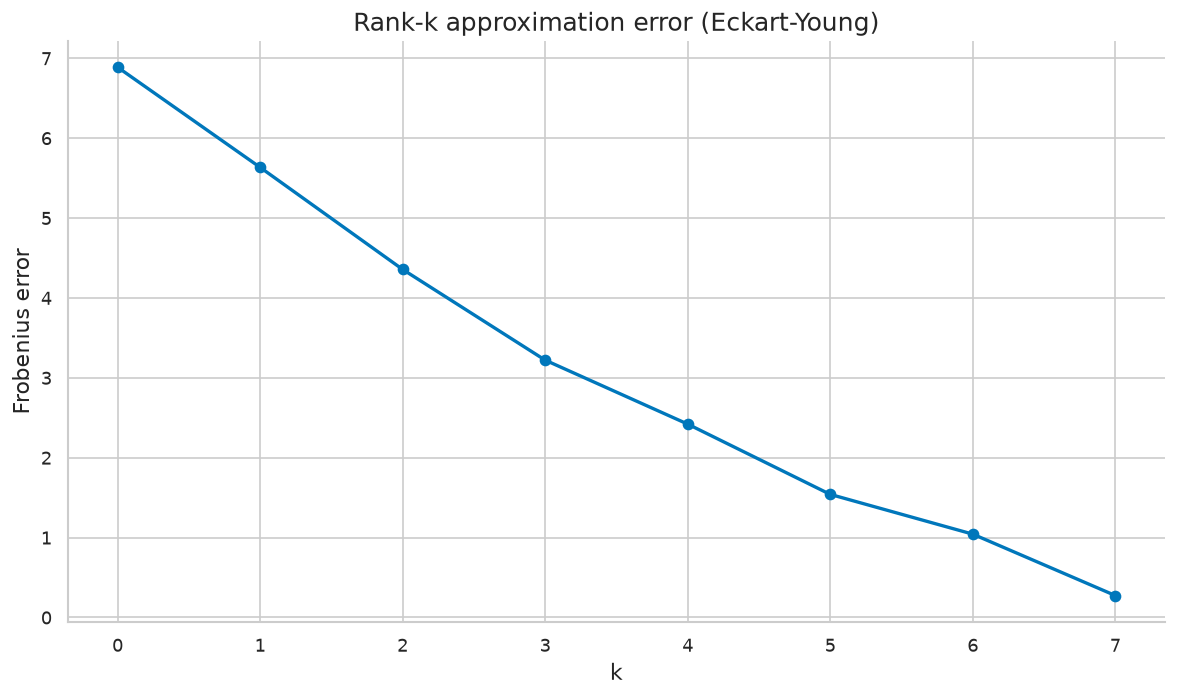

the singular values are the price list of rank reduction


In [16]:

rng = np.random.default_rng(42)
X = rng.normal(size=(10, 8)); U, s, Vt = la.svd(X, full_matrices=False)
errs = []
for k in range(0, 8):
    Xk = U[:, :k] @ np.diag(s[:k]) @ Vt[:k]
    errs.append(la.norm(X - Xk))
    tail = np.sqrt(np.sum(s[k:]**2))
    check_true(f"k={k}: achieved error equals discarded tail energy", abs(errs[-1] - tail) < 1e-10)
fig, ax = plt.subplots()
ax.plot(range(8), errs, marker='o', color=WONG[0])
ax.set_title("Rank-k approximation error (Eckart-Young)"); ax.set_xlabel("k"); ax.set_ylabel("Frobenius error")
plt.tight_layout(); plt.show()
print("the singular values are the price list of rank reduction")

## Appended Demo 5: Numerical Rank Depends on the Threshold

Exact rank counts nonzero singular values; numerical rank counts those above a threshold. A matrix with geometrically decaying spectrum has a different honest rank at every tolerance.

In [17]:

U, _ = la.qr(np.random.default_rng(42).normal(size=(8, 8)))
V, _ = la.qr(np.random.default_rng(7).normal(size=(8, 8)))
s = 10.0 ** np.arange(0, -8, -1.0)
A = U @ np.diag(s) @ V.T
for tol, expected in [(1e-2, 3), (1e-4, 5), (1e-6, 7)]:
    check_true(f"tol={tol:.0e}: numerical rank is {expected}", int(np.sum(la.svd(A, compute_uv=False) > tol)) == expected)
print(f"exact rank is 8; usable rank is a modelling decision, singular values: {np.array2string(s, precision=0)}")

PASS: tol=1e-02: numerical rank is 3
PASS: tol=1e-04: numerical rank is 5
PASS: tol=1e-06: numerical rank is 7
exact rank is 8; usable rank is a modelling decision, singular values: [1. 0. 0. 0. 0. 0. 0. 0.]


## Appended Demo 6: Rank Factorisation A = CF

Any rank-r matrix factors as A = CF with C holding r independent columns of A and F of full row rank. Column-pivoted QR finds the columns; least squares finds F.

In [18]:

rng = np.random.default_rng(42)
A = rng.normal(size=(8, 3)) @ rng.normal(size=(3, 6))
r = la.matrix_rank(A)
Q, R, P = sla.qr(A, pivoting=True)
C = A[:, P[:r]]
F, *_ = la.lstsq(C, A, rcond=None)
check_close("A = C F reconstructs the matrix", C @ F, A, 1e-10)
check_true("factor shapes are (8 x r)(r x 6)", C.shape == (8, r) and F.shape == (r, 6))
print(f"rank {r}: stored as {C.size + F.size} numbers instead of {A.size}")

PASS: A = C F reconstructs the matrix (max err 8.88e-16, tol 1e-10)
PASS: factor shapes are (8 x r)(r x 6)
rank 3: stored as 42 numbers instead of 48


## Appended Demo 7: LoRA Rank Is a Budget, Not a Metaphor

A LoRA update BA has rank at most r and costs r(d + k) parameters against dk for the full update. The rank bound and the parameter accounting are both checked arithmetically.

In [19]:

rng = np.random.default_rng(42)
d, k, r = 64, 64, 4
B = rng.normal(size=(d, r)); A_ = rng.normal(size=(r, k))
update = B @ A_
check_true("LoRA update rank <= r", la.matrix_rank(update) <= r)
full = d * k; lora = r * (d + k)
check_true(f"parameter cost: LoRA {lora} < full {full}", lora < full)
print(f"full update {full} params; rank-{r} LoRA {lora} params ({100*lora/full:.1f}%)")

PASS: LoRA update rank <= r
PASS: parameter cost: LoRA 512 < full 4096
full update 4096 params; rank-4 LoRA 512 params (12.5%)


## Appended Demo 8: Gram Rank and Generic Rank

rank(A^T A) = rank(A) always - forming the Gram matrix loses information numerically but not algebraically. A random Gaussian matrix has full generic rank min(m, n).

In [20]:

rng = np.random.default_rng(42)
A = rng.normal(size=(9, 6)) @ np.diag([1., 1., 1., 1., 0., 0.])  # rank 4
check_true("rank(A^T A) = rank(A)", la.matrix_rank(A.T @ A) == la.matrix_rank(A) == 4)
G = rng.normal(size=(7, 11))
check_true("random 7x11 Gaussian matrix has generic rank 7", la.matrix_rank(G) == 7)
print("rank deficiency must be built in; randomness almost never creates it")

PASS: rank(A^T A) = rank(A)
PASS: random 7x11 Gaussian matrix has generic rank 7
rank deficiency must be built in; randomness almost never creates it


---

## 11. What to Notice

- Rank is the dimension of the image, not the count of non-zero entries.
- Row reduction gives rank exactly in symbolic settings; SVD gives rank robustly in numerical settings.
- Rank-nullity is the cleanest information-flow identity for linear maps.
- Low-rank factorization means the matrix truly passes through a smaller latent space.
- Truncated SVD is optimal, not heuristic, for low-rank approximation in Frobenius and spectral norm.
- Stable rank and numerical rank are often more informative than exact rank in ML diagnostics.
- LoRA, attention projections, and latent bottlenecks are all rank engineering.

### References used for this notebook

- [notes.md](notes.md) in this chapter
- [MIT 18.06 Linear Algebra](https://web.mit.edu/18.06/www/)
- [Stanford EE263](https://stanford.edu/class/ee263/)
- [Hu et al. (2021), LoRA](https://arxiv.org/abs/2106.09685)
- [DeepSeek-V2 Technical Report](https://arxiv.org/abs/2405.04434)
- [DeepSeek-V3 Technical Report](https://arxiv.org/abs/2412.19437)
- [Aghajanyan et al. (2020), Intrinsic Dimensionality](https://arxiv.org/abs/2012.13255)
- [Halko, Martinsson, and Tropp (2011), Randomized Matrix Decompositions](https://arxiv.org/abs/0909.4061)
- [Gavish and Donoho (2014), Optimal Hard Threshold](https://arxiv.org/abs/1305.5870)

Next step: build the exercise notebook so the theory turns into procedural fluency.